In [22]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')
print("Hello Kaggle")

Hello Kaggle


In [23]:
!nvidia-smi

Mon Nov  2 14:53:55 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [24]:
!curl -sI https://huggingface.co | head -n 1

HTTP/2 200 


In [25]:
from kaggle_secrets import UserSecretsClient
token = UserSecretsClient().get_secret("HF_TOKEN")
print("Token loaded, starts with:", token[:3])

Token loaded, starts with: hf_


In [26]:
!pip install -q huggingface_hub
from huggingface_hub import login, whoami
login(token)
print("Logged in as:", whoami()["name"])

Logged in as: Lakshitha-MR-sd15


In [38]:
!ls /kaggle/input

In [31]:
import os, json, glob
from PIL import Image
from transformers import BlipProcessor, BlipForConditionalGeneration

SRC = "/kaggle/input/my-style-data"   # change if your folder name differs
OUT = "/kaggle/working/train"
TRIGGER = "mystyle"
os.makedirs(OUT, exist_ok=True)

processor = BlipProcessor.from_pretrained("Salesforce/blip-image-captioning-base")
model = BlipForConditionalGeneration.from_pretrained("Salesforce/blip-image-captioning-base").to("cuda")

exts = (".jpg", ".jpeg", ".png", ".webp")
files = sorted(f for f in glob.glob(SRC + "/**/*", recursive=True) if f.lower().endswith(exts))
print("Images found:", len(files))

rows = []
for i, f in enumerate(files):
    img = Image.open(f).convert("RGB")
    w, h = img.size
    s = min(w, h)
    img = img.crop(((w - s) // 2, (h - s) // 2, (w + s) // 2, (h + s) // 2)).resize((512, 512))
    name = f"img{i:03d}.png"
    img.save(f"{OUT}/{name}")
    inputs = processor(img, return_tensors="pt").to("cuda")
    out = model.generate(**inputs, max_new_tokens=30)
    caption = processor.decode(out[0], skip_special_tokens=True)
    rows.append({"file_name": name, "text": f"{TRIGGER}, {caption}"})

with open(f"{OUT}/metadata.jsonl", "w") as fp:
    for r in rows:
        fp.write(json.dumps(r) + "\n")

for r in rows[:5]:
    print(r)

preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  990MB            

model.safetensors: downloading bytes:           |  0.00B            

Images found: 0


In [39]:
from IPython.display import display
display(Image.open("/kaggle/working/train/img000.png"))

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/train/img000.png'

In [41]:
!ls -R /kaggle/input | head -n 40

/kaggle/input:


In [42]:
import glob
exts = (".jpg", ".jpeg", ".png", ".webp")
files = sorted(f for f in glob.glob("/kaggle/input/**/*", recursive=True) if f.lower().endswith(exts))
print("Images found:", len(files))
print(files[:3])

Images found: 0
[]


In [43]:
!cd /kaggle/working && unzip -q -o /kaggle/input/*/*.zip -d /kaggle/working/unzipped

unzip:  cannot find or open /kaggle/input/*/*.zip, /kaggle/input/*/*.zip.zip or /kaggle/input/*/*.zip.ZIP.

No zipfiles found.


In [44]:
!ls /kaggle/input
import glob
files = sorted(glob.glob("/kaggle/input/**/*.png", recursive=True))
print("Images found:", len(files))
print(files[:2])

Images found: 0
[]


In [45]:
!ls -la /kaggle/input

total 12
drwxr-xr-x 3 root root 4096 Nov  2 15:00 .
drwxr-xr-x 5 root root 4096 Nov  2 14:08 ..
drwxr-xr-x 3 root root 4096 Nov  2 15:00 datasets


In [46]:
import glob
files = sorted(glob.glob("/kaggle/input/**/*.png", recursive=True))
print("Images found:", len(files))
print(files[:2])

Images found: 30
['/kaggle/input/datasets/mrlakshitha/my-style-data/Screenshot 2026-09-17 112157.png', '/kaggle/input/datasets/mrlakshitha/my-style-data/Screenshot 2026-09-17 112537.png']


In [47]:
files = sorted(glob.glob("/kaggle/working/**/*.png", recursive=True))
print(len(files))

0


In [48]:
import glob
files = sorted(glob.glob("/kaggle/input/**/*.png", recursive=True))
print("Images found:", len(files))
print(files[:2])

Images found: 30
['/kaggle/input/datasets/mrlakshitha/my-style-data/Screenshot 2026-09-17 112157.png', '/kaggle/input/datasets/mrlakshitha/my-style-data/Screenshot 2026-09-17 112537.png']


In [49]:
import os, json, glob
from PIL import Image
from transformers import BlipProcessor, BlipForConditionalGeneration

SRC = "/kaggle/input/datasets/mrlakshitha/my-style-data"
OUT = "/kaggle/working/train"
TRIGGER = "mystyle"
os.makedirs(OUT, exist_ok=True)

processor = BlipProcessor.from_pretrained("Salesforce/blip-image-captioning-base")
model = BlipForConditionalGeneration.from_pretrained("Salesforce/blip-image-captioning-base").to("cuda")

exts = (".jpg", ".jpeg", ".png", ".webp")
files = sorted(f for f in glob.glob(SRC + "/**/*", recursive=True) if f.lower().endswith(exts))
print("Images found:", len(files))

rows = []
for i, f in enumerate(files):
    img = Image.open(f).convert("RGB")
    w, h = img.size
    s = min(w, h)
    img = img.crop(((w - s) // 2, (h - s) // 2, (w + s) // 2, (h + s) // 2)).resize((512, 512))
    name = f"img{i:03d}.png"
    img.save(f"{OUT}/{name}")
    inputs = processor(img, return_tensors="pt").to("cuda")
    out = model.generate(**inputs, max_new_tokens=30)
    caption = processor.decode(out[0], skip_special_tokens=True)
    rows.append({"file_name": name, "text": f"{TRIGGER}, {caption}"})

with open(f"{OUT}/metadata.jsonl", "w") as fp:
    for r in rows:
        fp.write(json.dumps(r) + "\n")

for r in rows[:5]:
    print(r)

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

Images found: 30
{'file_name': 'img000.png', 'text': 'mystyle, the interface of the interface interface for the interface interface'}
{'file_name': 'img001.png', 'text': 'mystyle, the text on the page is a white background with a green background'}
{'file_name': 'img002.png', 'text': 'mystyle, the billing screen with the billing button highlighted'}
{'file_name': 'img003.png', 'text': 'mystyle, the website for the new website, with the new website and the new website'}
{'file_name': 'img004.png', 'text': 'mystyle, a table with a number of numbers and numbers'}


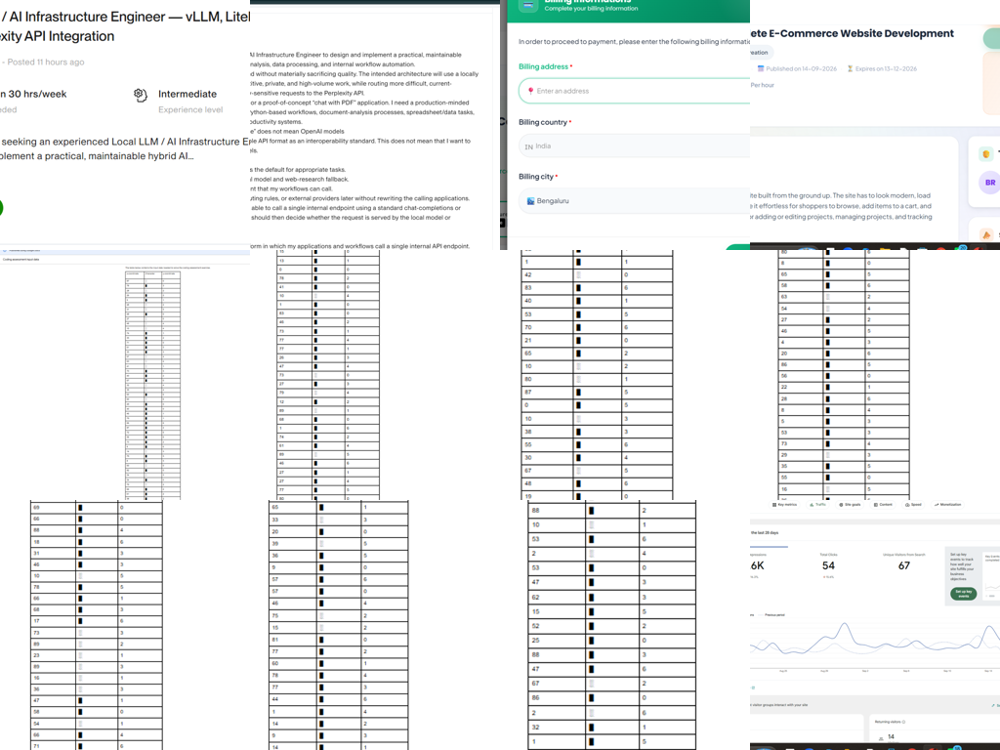

In [50]:
from IPython.display import display
sheet = Image.new("RGB", (256 * 4, 256 * 3))
for k in range(min(12, len(rows))):
    im = Image.open(f"{OUT}/{rows[k]['file_name']}").resize((256, 256))
    sheet.paste(im, ((k % 4) * 256, (k // 4) * 256))
display(sheet)

In [51]:
import torch, gc
try:
    del model, processor
except NameError:
    pass
gc.collect(); torch.cuda.empty_cache()

!git clone -q https://github.com/huggingface/diffusers /kaggle/working/diffusers
!pip install -q /kaggle/working/diffusers peft accelerate transformers datasets ftfy

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [52]:
!ls /kaggle/working/train | head -n 5
!head -n 2 /kaggle/working/train/metadata.jsonl

img000.png
img001.png
img002.png
img003.png
img004.png
{"file_name": "img000.png", "text": "mystyle, the interface of the interface interface for the interface interface"}
{"file_name": "img001.png", "text": "mystyle, the text on the page is a white background with a green background"}


In [53]:
!CUDA_VISIBLE_DEVICES=0 accelerate launch --num_processes=1 --mixed_precision=fp16 \
  /kaggle/working/diffusers/examples/text_to_image/train_text_to_image_lora.py \
  --pretrained_model_name_or_path="stable-diffusion-v1-5/stable-diffusion-v1-5" \
  --train_data_dir="/kaggle/working/train" \
  --caption_column="text" \
  --resolution=512 --center_crop --random_flip \
  --train_batch_size=1 --gradient_accumulation_steps=4 \
  --max_train_steps=50 --learning_rate=1e-4 \
  --lr_scheduler="cosine" --lr_warmup_steps=0 \
  --rank=16 --seed=42 \
  --output_dir="/kaggle/working/test_lora"

The following values were not passed to `accelerate launch` and had defaults used instead:
	`--num_machines` was set to a value of `1`
	`--dynamo_backend` was set to a value of `'no'`
To avoid this warning pass in values for each of the problematic parameters or run `accelerate config`.
11/02/2026 15:05:15 - INFO - __main__ - [RANK 0] Distributed environment: DistributedType.NO
Num processes: 1
Process index: 0
Local process index: 0
Device: cuda

Mixed precision type: fp16

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
11/02/2026 15:05:15 - INFO - httpx - HTTP Request: HEAD https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5/resolve/main/scheduler/scheduler_config.json "HTTP/1.1 307 Temporary Redirect"
11/02/2026 15:05:15 - INFO - httpx - HTTP Request: HEAD 

In [55]:
from huggingface_hub import HfApi, create_repo, login
from kaggle_secrets import UserSecretsClient
token = UserSecretsClient().get_secret("HF_TOKEN")
login(token)

repo = "YOUR_HF_USERNAME/mystyle-lora-sd15"
create_repo(repo, token=token, exist_ok=True)
HfApi().upload_file(
    path_or_fileobj="/kaggle/working/my_style_lora/pytorch_lora_weights.safetensors",
    path_in_repo="mystyle_lora.safetensors",
    repo_id=repo, token=token)
print("Uploaded to https://huggingface.co/" + repo)

HfHubHTTPError: (Request ID: Root=1-6ae8a6e0-56efc52d5144b626789d0a15;9c86e20a-be0a-4b74-9d4a-ff2fc7d97e5c)

403 Forbidden: You don't have the rights to create a model under the namespace "YOUR_HF_USERNAME".
Cannot access content at: https://huggingface.co/api/repos/create.
Make sure your token has the correct permissions.

In [1]:
from diffusers import StableDiffusionPipeline
import torch
pipe = StableDiffusionPipeline.from_pretrained("stable-diffusion-v1-5/stable-diffusion-v1-5", torch_dtype=torch.float16).to("cuda")
pipe.load_lora_weights("/kaggle/working/my_style_lora")
image = pipe("mystyle, a cat sitting on a chair", num_inference_steps=30, guidance_scale=7.5).images[0]
image

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

HFValidationError: Repo id must be in the form 'repo_name' or 'namespace/repo_name': '/kaggle/working/my_style_lora'. Use `repo_type` argument if needed.

In [2]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [3]:
!CUDA_VISIBLE_DEVICES=0 accelerate launch --num_processes=1 --mixed_precision=fp16 \
  /kaggle/working/diffusers/examples/text_to_image/train_text_to_image_lora.py \
  --pretrained_model_name_or_path="stable-diffusion-v1-5/stable-diffusion-v1-5" \
  --train_data_dir="/kaggle/working/train" \
  --caption_column="text" \
  --resolution=512 --center_crop --random_flip \
  --train_batch_size=1 --gradient_accumulation_steps=4 \
  --max_train_steps=50 --learning_rate=1e-4 \
  --lr_scheduler="cosine" --lr_warmup_steps=0 \
  --rank=16 --seed=42 \
  --output_dir="/kaggle/working/test_lora"

The following values were not passed to `accelerate launch` and had defaults used instead:
	`--num_machines` was set to a value of `1`
	`--dynamo_backend` was set to a value of `'no'`
To avoid this warning pass in values for each of the problematic parameters or run `accelerate config`.
/usr/bin/python3: can't open file '/kaggle/working/diffusers/examples/text_to_image/train_text_to_image_lora.py': [Errno 2] No such file or directory
Traceback (most recent call last):
  File "/usr/local/bin/accelerate", line 10, in <module>
    sys.exit(main())
             ~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/accelerate/commands/accelerate_cli.py", line 50, in main
    args.func(args)
    ~~~~~~~~~^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/accelerate/commands/launch.py", line 1407, in launch_command
    simple_launcher(args)
    ~~~~~~~~~~~~~~~^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/accelerate/commands/launch.py", line 993, in simple_launcher
    raise subp

In [1]:
!ls -lh /kaggle/working
!ls -lh /kaggle/working/test_lora
!ls -lh /kaggle/working/my_style_lora

total 0
ls: cannot access '/kaggle/working/test_lora': No such file or directory
ls: cannot access '/kaggle/working/my_style_lora': No such file or directory


In [2]:
import torch
from diffusers import StableDiffusionPipeline

pipe = StableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5", dtype=torch.float16).to("cuda")
pipe.load_lora_weights("/kaggle/working/my_style_lora",
                       weight_name="pytorch_lora_weights.safetensors")

image = pipe("mystyle, a cat sitting on a chair",
             num_inference_steps=30, guidance_scale=7.5).images[0]
image

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

OSError: We couldn't connect to 'https://huggingface.co' to load this model, couldn't find it in the cached files and it looks like /kaggle/working/my_style_lora is not the path to a directory containing a file named pytorch_lora_weights.safetensors or 
Checkout your internet connection or see how to run the library in offline mode at 'https://huggingface.co/docs/diffusers/installation#offline-mode'.

In [16]:
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login
login(UserSecretsClient().get_secret("HF_TOKEN"))

In [17]:
!nvidia-smi | head -n 12
!ls /kaggle/input/datasets/mrlakshitha/my-style-data | head -n 3

Tue Nov  3 03:49:02 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   60C    P0             29W /   70W |    2795MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [18]:
import os, json, glob
from PIL import Image
from transformers import BlipProcessor, BlipForConditionalGeneration

SRC = "/kaggle/input/datasets/mrlakshitha/my-style-data"
OUT = "/kaggle/working/train"
TRIGGER = "mystyle"
os.makedirs(OUT, exist_ok=True)

processor = BlipProcessor.from_pretrained("Salesforce/blip-image-captioning-base")
model = BlipForConditionalGeneration.from_pretrained("Salesforce/blip-image-captioning-base").to("cuda")

exts = (".jpg", ".jpeg", ".png", ".webp")
files = sorted(f for f in glob.glob(SRC + "/**/*", recursive=True) if f.lower().endswith(exts))
print("Images found:", len(files))

rows = []
for i, f in enumerate(files):
    img = Image.open(f).convert("RGB")
    w, h = img.size
    s = min(w, h)
    img = img.crop(((w - s) // 2, (h - s) // 2, (w + s) // 2, (h + s) // 2)).resize((512, 512))
    name = f"img{i:03d}.png"
    img.save(f"{OUT}/{name}")
    inputs = processor(img, return_tensors="pt").to("cuda")
    out = model.generate(**inputs, max_new_tokens=30)
    caption = processor.decode(out[0], skip_special_tokens=True)
    rows.append({"file_name": name, "text": f"{TRIGGER}, {caption}"})

with open(f"{OUT}/metadata.jsonl", "w") as fp:
    for r in rows:
        fp.write(json.dumps(r) + "\n")
print("Done:", len(rows), "captions")

# free GPU memory for training
import torch, gc
del model, processor
gc.collect(); torch.cuda.empty_cache()

preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  990MB            

model.safetensors: downloading bytes:           |  0.00B            

Images found: 30
Done: 30 captions


In [19]:
!git clone -q https://github.com/huggingface/diffusers /kaggle/working/diffusers
!pip install -q /kaggle/working/diffusers peft accelerate transformers datasets ftfy
!pip uninstall -y torchao
!ls /kaggle/working

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0
diffusers  train


In [20]:
!CUDA_VISIBLE_DEVICES=0 accelerate launch --num_processes=1 --mixed_precision=fp16 \
  /kaggle/working/diffusers/examples/text_to_image/train_text_to_image_lora.py \
  --pretrained_model_name_or_path="stable-diffusion-v1-5/stable-diffusion-v1-5" \
  --train_data_dir="/kaggle/working/train" \
  --caption_column="text" \
  --resolution=512 --center_crop --random_flip \
  --train_batch_size=1 --gradient_accumulation_steps=4 \
  --max_train_steps=50 --learning_rate=1e-4 \
  --lr_scheduler="cosine" --lr_warmup_steps=0 \
  --rank=16 --seed=42 \
  --output_dir="/kaggle/working/test_lora"

!ls -lh /kaggle/working/test_lora

The following values were not passed to `accelerate launch` and had defaults used instead:
	`--num_machines` was set to a value of `1`
	`--dynamo_backend` was set to a value of `'no'`
To avoid this warning pass in values for each of the problematic parameters or run `accelerate config`.
11/03/2026 03:51:01 - INFO - __main__ - [RANK 0] Distributed environment: DistributedType.NO
Num processes: 1
Process index: 0
Local process index: 0
Device: cuda

Mixed precision type: fp16

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
11/03/2026 03:51:01 - INFO - httpx - HTTP Request: HEAD https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5/resolve/main/scheduler/scheduler_config.json "HTTP/1.1 307 Temporary Redirect"
11/03/2026 03:51:01 - INFO - httpx - HTTP Request: HEAD 

In [21]:
!CUDA_VISIBLE_DEVICES=0 accelerate launch --num_processes=1 --mixed_precision=fp16 \
  /kaggle/working/diffusers/examples/text_to_image/train_text_to_image_lora.py \
  --mixed_precision="fp16" \
  --pretrained_model_name_or_path="stable-diffusion-v1-5/stable-diffusion-v1-5" \
  --train_data_dir="/kaggle/working/train" \
  --caption_column="text" \
  --resolution=512 --center_crop --random_flip \
  --train_batch_size=1 --gradient_accumulation_steps=4 \
  --max_train_steps=50 --learning_rate=1e-4 \
  --lr_scheduler="cosine" --lr_warmup_steps=0 \
  --rank=16 --seed=42 \
  --output_dir="/kaggle/working/test_lora"

!ls -lh /kaggle/working/test_lora

The following values were not passed to `accelerate launch` and had defaults used instead:
	`--num_machines` was set to a value of `1`
	`--dynamo_backend` was set to a value of `'no'`
To avoid this warning pass in values for each of the problematic parameters or run `accelerate config`.
11/03/2026 03:52:58 - INFO - __main__ - [RANK 0] Distributed environment: DistributedType.NO
Num processes: 1
Process index: 0
Local process index: 0
Device: cuda

Mixed precision type: fp16

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
11/03/2026 03:52:58 - INFO - httpx - HTTP Request: HEAD https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5/resolve/main/scheduler/scheduler_config.json "HTTP/1.1 307 Temporary Redirect"
11/03/2026 03:52:58 - INFO - httpx - HTTP Request: HEAD 

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/30 [00:00<?, ?it/s]

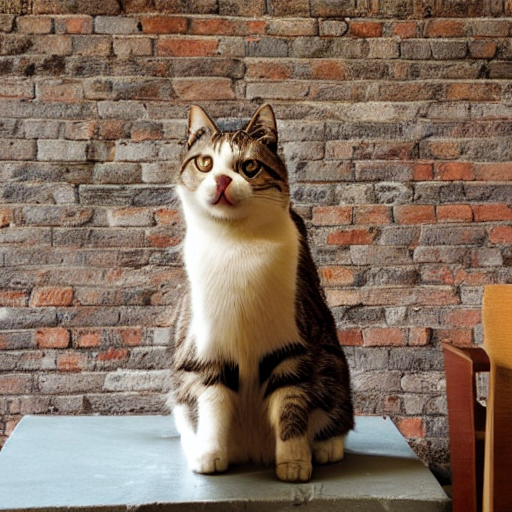

In [22]:
import torch
from diffusers import StableDiffusionPipeline

pipe = StableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5", dtype=torch.float16).to("cuda")
pipe.load_lora_weights("/kaggle/working/test_lora",
                       weight_name="pytorch_lora_weights.safetensors")

image = pipe("mystyle, a cat sitting on a chair",
             num_inference_steps=30, guidance_scale=7.5).images[0]
image

In [24]:
del pipe
import gc; gc.collect(); torch.cuda.empty_cache()

NameError: name 'pipe' is not defined

In [25]:
!CUDA_VISIBLE_DEVICES=0 accelerate launch --num_processes=1 --mixed_precision=fp16 \
  /kaggle/working/diffusers/examples/text_to_image/train_text_to_image_lora.py \
  --mixed_precision="fp16" \
  --pretrained_model_name_or_path="stable-diffusion-v1-5/stable-diffusion-v1-5" \
  --train_data_dir="/kaggle/working/train" \
  --caption_column="text" \
  --resolution=512 --center_crop --random_flip \
  --train_batch_size=1 --gradient_accumulation_steps=4 \
  --max_train_steps=1000 --learning_rate=1e-4 \
  --lr_scheduler="cosine" --lr_warmup_steps=0 \
  --rank=16 --seed=42 \
  --output_dir="/kaggle/working/my_style_lora"

!ls -lh /kaggle/working/my_style_lora

The following values were not passed to `accelerate launch` and had defaults used instead:
	`--num_machines` was set to a value of `1`
	`--dynamo_backend` was set to a value of `'no'`
To avoid this warning pass in values for each of the problematic parameters or run `accelerate config`.
11/03/2026 04:12:36 - INFO - __main__ - [RANK 0] Distributed environment: DistributedType.NO
Num processes: 1
Process index: 0
Local process index: 0
Device: cuda

Mixed precision type: fp16

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
11/03/2026 04:12:36 - INFO - httpx - HTTP Request: HEAD https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5/resolve/main/scheduler/scheduler_config.json "HTTP/1.1 307 Temporary Redirect"
11/03/2026 04:12:36 - INFO - httpx - HTTP Request: HEAD 

In [27]:
from huggingface_hub import HfApi, create_repo, login
from kaggle_secrets import UserSecretsClient

token = UserSecretsClient().get_secret("HF_TOKEN")
login(token)

repo = "YOUR_HF_USERNAME/mystyle-lora-sd15"
create_repo(repo, token=token, exist_ok=True)
HfApi().upload_file(
    path_or_fileobj="/kaggle/working/my_style_lora/pytorch_lora_weights.safetensors",
    path_in_repo="mystyle_lora.safetensors",
    repo_id=repo, token=token)
print("Uploaded: https://huggingface.co/" + repo)

HfHubHTTPError: (Request ID: Root=1-6ae96517-6afa597b171511410ed8f861;a056e4b0-1b8b-4267-84c0-dc194fe61181)

403 Forbidden: You don't have the rights to create a model under the namespace "YOUR_HF_USERNAME".
Cannot access content at: https://huggingface.co/api/repos/create.
Make sure your token has the correct permissions.

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

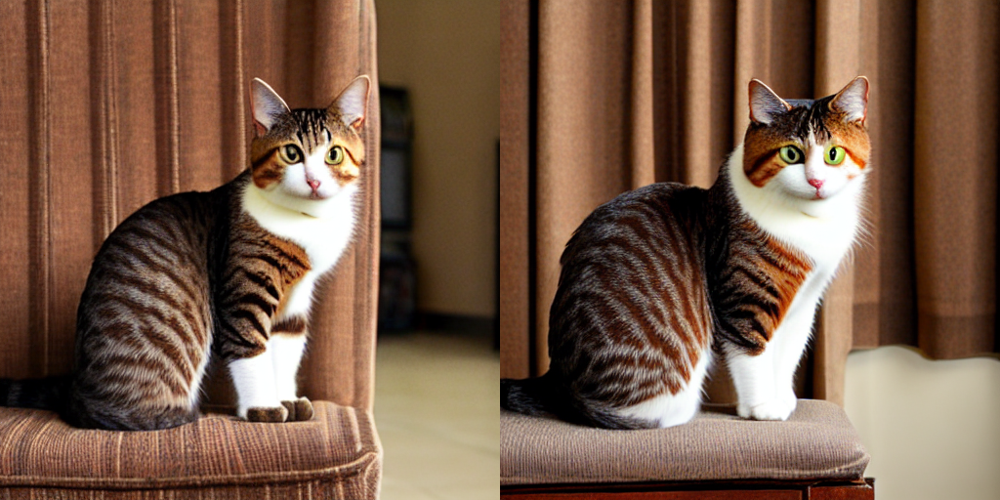

In [28]:
import torch
from diffusers import StableDiffusionPipeline

pipe = StableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5", dtype=torch.float16).to("cuda")
pipe.load_lora_weights("/kaggle/working/my_style_lora",
                       weight_name="pytorch_lora_weights.safetensors")

g = torch.Generator("cuda").manual_seed(1)
with_style = pipe("mystyle, a cat sitting on a chair", generator=g, num_inference_steps=30).images[0]
g = torch.Generator("cuda").manual_seed(1)
without = pipe("a cat sitting on a chair", generator=g, num_inference_steps=30).images[0]

from PIL import Image
sheet = Image.new("RGB", (1024, 512))
sheet.paste(without, (0, 0)); sheet.paste(with_style, (512, 0))
sheet

In [29]:
from huggingface_hub import whoami
print(whoami(token)["name"])

Lakshitha-MR-sd15


In [30]:
!ls -lh /kaggle/working/my_style_lora

total 13M
drwxr-xr-x 2 root root 4.0K Nov  3 04:36 checkpoint-1000
drwxr-xr-x 2 root root 4.0K Nov  3 04:24 checkpoint-500
drwxr-xr-x 3 root root 4.0K Nov  3 04:12 logs
-rw------- 1 root root  13M Nov  3 04:36 pytorch_lora_weights.safetensors


In [31]:
from huggingface_hub import HfApi, create_repo, login, whoami
from kaggle_secrets import UserSecretsClient

token = UserSecretsClient().get_secret("HF_TOKEN")
login(token)

username = whoami(token)["name"]
repo = f"{username}/mystyle-lora-sd15"

create_repo(repo, token=token, exist_ok=True)
HfApi().upload_file(
    path_or_fileobj="/kaggle/working/my_style_lora/pytorch_lora_weights.safetensors",
    path_in_repo="mystyle_lora.safetensors",
    repo_id=repo, token=token)
print("Uploaded: https://huggingface.co/" + repo)

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Uploaded: https://huggingface.co/Lakshitha-MR-sd15/mystyle-lora-sd15


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

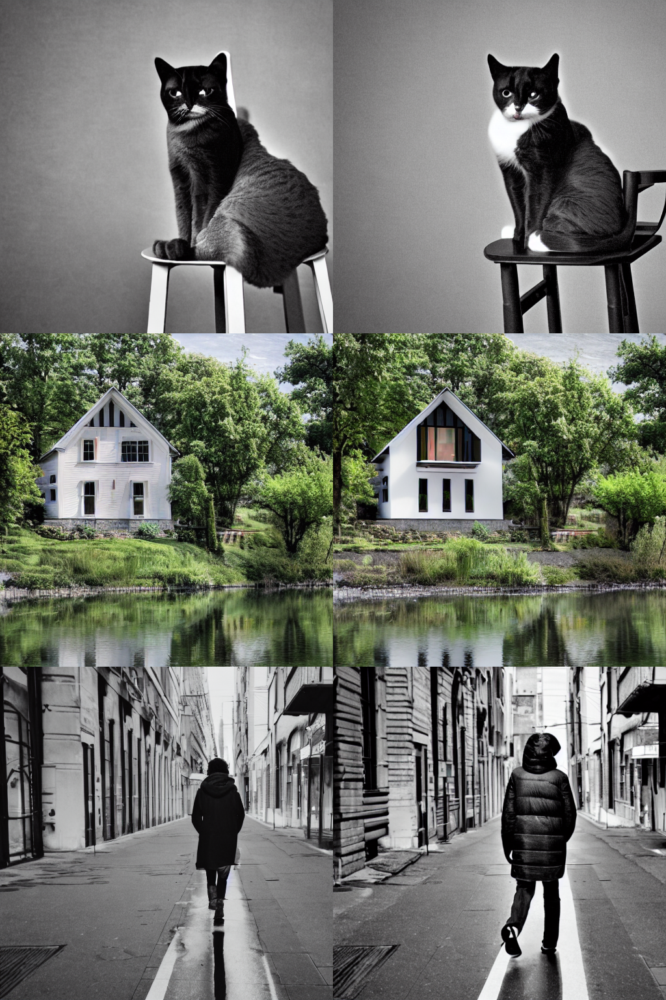

In [32]:
import torch
from diffusers import StableDiffusionPipeline
from PIL import Image

pipe = StableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5", dtype=torch.float16).to("cuda")
pipe.load_lora_weights("/kaggle/working/my_style_lora",
                       weight_name="pytorch_lora_weights.safetensors")

prompts = ["a cat sitting on a chair", "a house by a river", "a person walking in a city"]
sheet = Image.new("RGB", (1024, 512 * len(prompts)))

for row, p in enumerate(prompts):
    g = torch.Generator("cuda").manual_seed(7)
    plain = pipe(p, generator=g, num_inference_steps=30).images[0]
    g = torch.Generator("cuda").manual_seed(7)
    styled = pipe("mystyle, " + p, generator=g, num_inference_steps=30).images[0]
    sheet.paste(plain, (0, row * 512))
    sheet.paste(styled, (512, row * 512))

sheet

In [33]:
!git clone -q https://github.com/comfyanonymous/ComfyUI /kaggle/working/ComfyUI
!pip install -q -r /kaggle/working/ComfyUI/requirements.txt
!ls /kaggle/working/ComfyUI | head -n 5

agent_requirements.txt
AGENTS.md
alembic_db
alembic.ini
api_server


In [34]:
!wget -q -P /kaggle/working/ComfyUI/models/checkpoints https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5/resolve/main/v1-5-pruned-emaonly.safetensors

import shutil
from huggingface_hub import hf_hub_download, whoami
from kaggle_secrets import UserSecretsClient

token = UserSecretsClient().get_secret("HF_TOKEN")
user = whoami(token)["name"]
p = hf_hub_download(f"{user}/mystyle-lora-sd15", "mystyle_lora.safetensors", token=token)
shutil.copy(p, "/kaggle/working/ComfyUI/models/loras/mystyle_lora.safetensors")

!ls -lh /kaggle/working/ComfyUI/models/checkpoints /kaggle/working/ComfyUI/models/loras

mystyle_lora.safetensors: reconstructing file:   0%|          |  0.00B / 12.8MB            

mystyle_lora.safetensors: downloading bytes:           |  0.00B            

/kaggle/working/ComfyUI/models/checkpoints:
total 4.0G
-rw-r--r-- 1 root root    0 Nov  3 04:41 put_checkpoints_here
-rw-r--r-- 1 root root 4.0G Nov  3 04:42 v1-5-pruned-emaonly.safetensors

/kaggle/working/ComfyUI/models/loras:
total 13M
-rw-r--r-- 1 root root 13M Nov  3 04:42 mystyle_lora.safetensors
-rw-r--r-- 1 root root   0 Nov  3 04:41 put_loras_here


In [35]:
import subprocess, time
subprocess.Popen("cd /kaggle/working/ComfyUI && nohup python main.py --listen 127.0.0.1 --port 8188 > /kaggle/working/comfy.log 2>&1 &", shell=True)
time.sleep(40)
!tail -n 6 /kaggle/working/comfy.log

[INFO] 
[INFO] Using RAM pressure cache.
[INFO] ComfyUI is developed by Comfy Org. We also offer commercial products to deploy ComfyUI as scalable cloud endpoints. Visit platform.comfy.org/ascii for more information.
[INFO] Starting server

[INFO] To see the GUI go to: http://127.0.0.1:8188


In [36]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /kaggle/working/cloudflared
!chmod +x /kaggle/working/cloudflared
subprocess.Popen("nohup /kaggle/working/cloudflared tunnel --url http://127.0.0.1:8188 > /kaggle/working/tunnel.log 2>&1 &", shell=True)
time.sleep(12)
!grep -o 'https://[-a-z0-9]*\.trycloudflare\.com' /kaggle/working/tunnel.log | head -n 1

https://uncle-calendars-extraction-old.trycloudflare.com


In [37]:
!tail -n 15 /kaggle/working/comfy.log
!curl -s -o /dev/null -w "ComfyUI local status: %{http_code}\n" http://127.0.0.1:8188/

[INFO] comfyui-embedded-docs version: 0.5.15
[INFO] comfy-aimdo version: 0.6.0
[INFO] comfy-kitchen version: 0.2.40
[INFO] [Prompt Server] web root: /usr/local/lib/python3.13/dist-packages/comfyui_frontend_package/static
[INFO] Asset seeder disabled
[INFO] No OpenGL_accelerate module loaded: No module named 'OpenGL_accelerate'
[INFO] 
Import times for custom nodes:
[INFO]    0.0 seconds: /kaggle/working/ComfyUI/custom_nodes/websocket_image_save.py
[INFO] 
[INFO] Using RAM pressure cache.
[INFO] ComfyUI is developed by Comfy Org. We also offer commercial products to deploy ComfyUI as scalable cloud endpoints. Visit platform.comfy.org/ascii for more information.
[INFO] Starting server

[INFO] To see the GUI go to: http://127.0.0.1:8188
ComfyUI local status: 200


In [38]:
!tail -n 20 /kaggle/working/tunnel.log

2026-11-03T04:44:00Z INF +-------------------------------------------------------------------------------------+
2026-11-03T04:44:00Z INF |  COMPONENT         TARGET                     STATUS  DETAILS                       |
2026-11-03T04:44:00Z INF |  DNS Resolution    region1.v2.argotunnel.com  PASS    DNS Resolved successfully     |
2026-11-03T04:44:00Z INF |  DNS Resolution    region2.v2.argotunnel.com  PASS    DNS Resolved successfully     |
2026-11-03T04:44:00Z INF |  UDP Connectivity  region1.v2.argotunnel.com  PASS    QUIC connection successful    |
2026-11-03T04:44:00Z INF |  UDP Connectivity  region2.v2.argotunnel.com  PASS    QUIC connection successful    |
2026-11-03T04:44:00Z INF |  TCP Connectivity  region1.v2.argotunnel.com  PASS    HTTP/2 connection successful  |
2026-11-03T04:44:00Z INF |  TCP Connectivity  region2.v2.argotunnel.com  PASS    HTTP/2 connection successful  |
2026-11-03T04:44:00Z INF |  Cloudflare API    api.cloudflare.com:443     PASS    API is reachabl

In [39]:
!curl -s -o /dev/null -w "%{http_code}\n" https://YOUR-LINK.trycloudflare.com

000


In [40]:
!tail -n 30 /kaggle/working/comfy.log
!ps aux | grep "main.py" | grep -v grep

[INFO] Device: cuda:1 Tesla T4 : cudaMallocAsync
[INFO] Using async weight offloading with 2 streams
[INFO] Enabled pinned memory 14336
[INFO] Using pytorch attention
[INFO] aimdo: /project/src/control.c:283:INFO:comfy-aimdo inited for GPU: Tesla T4 (VRAM: 14911 MB)
[INFO] aimdo: /project/src/control.c:283:INFO:comfy-aimdo inited for GPU: Tesla T4 (VRAM: 14911 MB)
[INFO] DynamicVRAM support detected and enabled
[INFO] Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
[INFO] ComfyUI version: 0.43.0
[INFO] comfy-aimdo version: 0.6.0
[INFO] comfy-kitchen version: 0.2.40
[WARNING] ****** User settings have been changed to be stored on the server instead of browser storage. ******
[WARNING] ****** For multi-user setups add the --multi-user CLI argument to enable multiple user profiles. ******
[INFO] comfyui-frontend-package version: 1.57.6
[INFO] comfyui-workflow-templates version: 0.11.100
[INFO] comfyui-embedded-docs version: 0.5.15
[INFO] comfy-aimdo version: 0.6.0
[INFO

In [41]:
!cd /kaggle/working/ComfyUI && timeout 60 python main.py --listen 127.0.0.1 --port 8188

[INFO] setup plugin alembic.autogenerate.schemas
[INFO] setup plugin alembic.autogenerate.tables
[INFO] setup plugin alembic.autogenerate.types
[INFO] setup plugin alembic.autogenerate.constraints
[INFO] setup plugin alembic.autogenerate.defaults
[INFO] setup plugin alembic.autogenerate.comments
[INFO] setup plugin alembic.ext.checkconstraint_byname
[WARNING] WARNING: You need pytorch with cu130 or higher to use optimized CUDA operations.
WARNING WARNING WARNING
If you are on nvidia 20 series and above it is required that you update your pytorch to cu130 or higher.

[INFO] Found comfy_kitchen backend ascend: {'available': False, 'disabled': False, 'unavailable_reason': "torch-npu is not installed: No module named 'torch_npu'", 'capabilities': []}
[INFO] Found comfy_kitchen backend hip: {'available': False, 'disabled': False, 'unavailable_reason': 'PyTorch ROCm/HIP runtime not available', 'capabilities': []}
[INFO] Found comfy_kitchen backend triton: {'available': True, 'disabled': True

In [42]:
import subprocess, time
subprocess.Popen("cd /kaggle/working/ComfyUI && nohup python main.py --listen 127.0.0.1 --port 8188 > /kaggle/working/comfy.log 2>&1 &", shell=True)

for i in range(24):
    time.sleep(5)
    out = subprocess.run("curl -s -o /dev/null -w '%{http_code}' http://127.0.0.1:8188/", shell=True, capture_output=True, text=True).stdout
    if out == "200":
        print("ComfyUI is up after", (i + 1) * 5, "seconds")
        break
else:
    print("Not up yet. Last log lines:")
    print(subprocess.run("tail -n 15 /kaggle/working/comfy.log", shell=True, capture_output=True, text=True).stdout)

ComfyUI is up after 5 seconds


In [43]:
import subprocess, time, os, re

subprocess.run("pkill -f cloudflared", shell=True)   # stop any old tunnel

if not os.path.exists("/kaggle/working/cloudflared"):
    subprocess.run("wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /kaggle/working/cloudflared && chmod +x /kaggle/working/cloudflared", shell=True)

subprocess.Popen("nohup /kaggle/working/cloudflared tunnel --url http://127.0.0.1:8188 > /kaggle/working/tunnel.log 2>&1 &", shell=True)

link = None
for i in range(12):
    time.sleep(5)
    log = open("/kaggle/working/tunnel.log").read()
    m = re.search(r"https://[-a-z0-9]+\.trycloudflare\.com", log)
    if m:
        link = m.group(0)
        break
print("Your link:", link)

Your link: https://shanghai-extend-lawsuit-drinking.trycloudflare.com


In [44]:
!curl -s -o /dev/null -w "%{http_code}\n" {link}

000


In [45]:
import subprocess, re
def sh(c): return subprocess.run(c, shell=True, capture_output=True, text=True).stdout.strip()

print("1) ComfyUI local status:", sh("curl -s -o /dev/null -w '%{http_code}' http://127.0.0.1:8188/"))
print("2) ComfyUI process:", sh("ps aux | grep '[m]ain.py' | wc -l"), "running")
print("3) Tunnel process:", sh("ps aux | grep '[c]loudflared' | wc -l"), "running")
print("\n--- comfy.log (last 8 lines) ---\n" + sh("tail -n 8 /kaggle/working/comfy.log"))
print("\n--- tunnel.log (last 15 lines) ---\n" + sh("tail -n 15 /kaggle/working/tunnel.log"))
print("\nLink found:", re.findall(r"https://[-a-z0-9]+\.trycloudflare\.com", sh("cat /kaggle/working/tunnel.log")))

1) ComfyUI local status: 200
2) ComfyUI process: 1 running
3) Tunnel process: 1 running

--- comfy.log (last 8 lines) ---
Import times for custom nodes:
[INFO]    0.0 seconds: /kaggle/working/ComfyUI/custom_nodes/websocket_image_save.py
[INFO] 
[INFO] Using RAM pressure cache.
[INFO] ComfyUI is developed by Comfy Org. We also offer commercial products to deploy ComfyUI as scalable cloud endpoints. Visit platform.comfy.org/ascii for more information.
[INFO] Starting server

[ERROR] Port 8188 is already in use on address 127.0.0.1. Please close the other application or use a different port with --port.

--- tunnel.log (last 15 lines) ---
2026-11-03T04:48:11Z INF |  SUMMARY: Environment is healthy. cloudflared will use 'quic' as primary protocol.  |
2026-11-03T04:48:11Z INF +-------------------------------------------------------------------------------------+
2026-11-03T04:48:11Z INF precheck component="DNS Resolution" details="DNS Resolved successfully" run_id=cd41984e-aa46-4292-8df0-b4

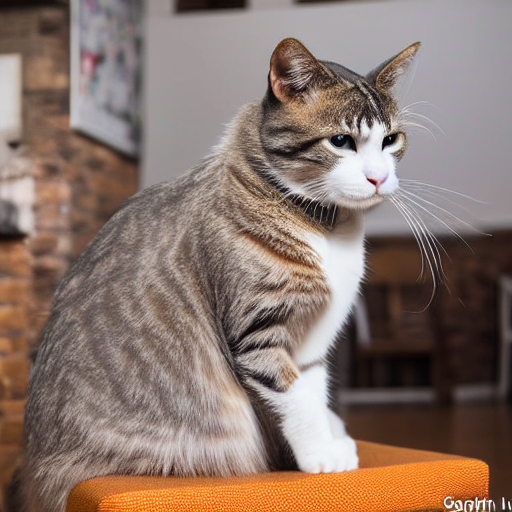

In [47]:
import json, time, urllib.request
from PIL import Image
from IPython.display import display

BASE = "http://127.0.0.1:8188"

def make_workflow(prompt, seed=42):
    return {
      "1": {"class_type": "CheckpointLoaderSimple",
            "inputs": {"ckpt_name": "v1-5-pruned-emaonly.safetensors"}},
      "2": {"class_type": "LoraLoader",
            "inputs": {"model": ["1", 0], "clip": ["1", 1],
                       "lora_name": "mystyle_lora.safetensors",
                       "strength_model": 1.0, "strength_clip": 1.0}},
      "3": {"class_type": "CLIPTextEncode",
            "inputs": {"text": prompt, "clip": ["2", 1]}},
      "4": {"class_type": "CLIPTextEncode",
            "inputs": {"text": "blurry, low quality", "clip": ["2", 1]}},
      "5": {"class_type": "EmptyLatentImage",
            "inputs": {"width": 512, "height": 512, "batch_size": 1}},
      "6": {"class_type": "KSampler",
            "inputs": {"model": ["2", 0], "seed": seed, "steps": 25, "cfg": 7.5,
                       "sampler_name": "euler", "scheduler": "normal",
                       "positive": ["3", 0], "negative": ["4", 0],
                       "latent_image": ["5", 0], "denoise": 1.0}},
      "7": {"class_type": "VAEDecode",
            "inputs": {"samples": ["6", 0], "vae": ["1", 2]}},
      "8": {"class_type": "SaveImage",
            "inputs": {"images": ["7", 0], "filename_prefix": "mystyle"}}
    }

def generate(prompt, seed=42):
    wf = make_workflow(prompt, seed)
    req = urllib.request.Request(BASE + "/prompt",
          data=json.dumps({"prompt": wf}).encode(),
          headers={"Content-Type": "application/json"})
    pid = json.loads(urllib.request.urlopen(req).read())["prompt_id"]
    for _ in range(150):
        hist = json.loads(urllib.request.urlopen(f"{BASE}/history/{pid}").read())
        if pid in hist:
            imgs = hist[pid]["outputs"]["8"]["images"]
            return [Image.open("/kaggle/working/ComfyUI/output/" + i["filename"]) for i in imgs]
        time.sleep(2)
    raise TimeoutError("Image not ready after 5 minutes")

# save the workflow file for your GitHub repo
json.dump(make_workflow("mystyle, a cat sitting on a chair"),
          open("/kaggle/working/mystyle_workflow_api.json", "w"), indent=2)

for img in generate("mystyle, a cat sitting on a chair", seed=1):
    display(img)

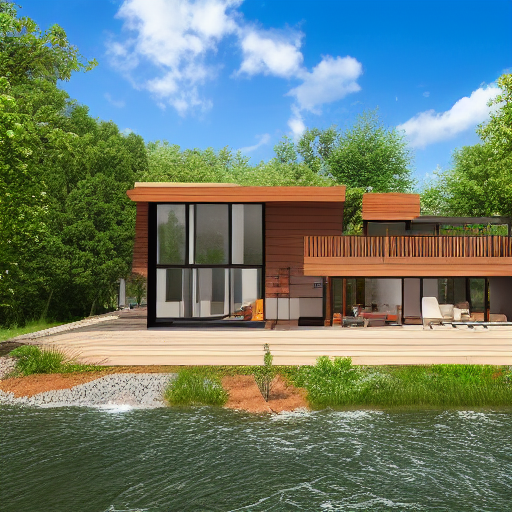

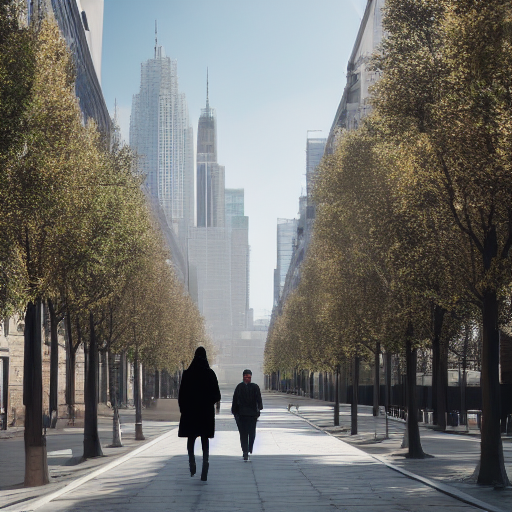

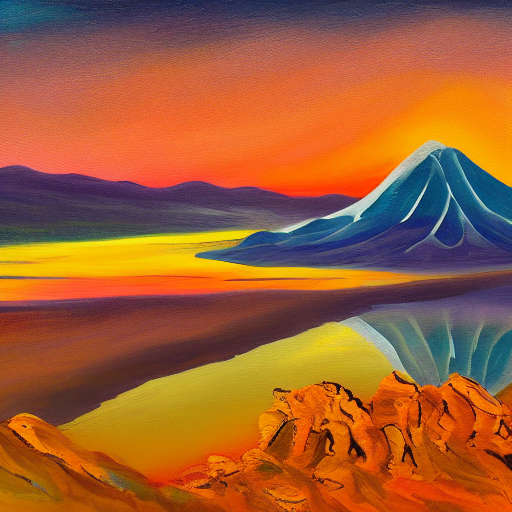

In [48]:
for i, p in enumerate(["mystyle, a house by a river", "mystyle, a person walking in a city",
                       "mystyle, a mountain at sunset"]):
    display(generate(p, seed=i + 10)[0])

In [49]:
import os, glob, shutil
from huggingface_hub import HfApi, whoami
from kaggle_secrets import UserSecretsClient

token = UserSecretsClient().get_secret("HF_TOKEN")
user = whoami(token)["name"]
repo = f"{user}/mystyle-lora-sd15"

pub = "/kaggle/working/publish"
os.makedirs(pub + "/samples", exist_ok=True)

imgs = sorted(glob.glob("/kaggle/working/ComfyUI/output/mystyle_*.png"), key=os.path.getmtime)[-6:]
for i, f in enumerate(imgs):
    shutil.copy(f, f"{pub}/samples/sample_{i+1}.png")
shutil.copy("/kaggle/working/mystyle_workflow_api.json", pub + "/mystyle_workflow_api.json")

gallery = "\n".join(f"![sample {i+1}](samples/sample_{i+1}.png)" for i in range(len(imgs)))

readme = f"""---
license: creativeml-openrail-m
base_model: stable-diffusion-v1-5/stable-diffusion-v1-5
library_name: diffusers
pipeline_tag: text-to-image
tags:
- lora
- stable-diffusion
- text-to-image
- comfyui
---

# mystyle LoRA (Stable Diffusion 1.5)

A small style LoRA trained on 30 images, trained and tested entirely on free Kaggle GPUs.

**Trigger word:** `mystyle`

## Samples
{gallery}

## How to use
**ComfyUI:** put `mystyle_lora.safetensors` in `models/loras`, add a Load LoRA node after the checkpoint loader, and start your prompt with `mystyle,`. A ready workflow is included: `mystyle_workflow_api.json`.

**diffusers:**
```python
import torch
from diffusers import StableDiffusionPipeline
pipe = StableDiffusionPipeline.from_pretrained("stable-diffusion-v1-5/stable-diffusion-v1-5", dtype=torch.float16).to("cuda")
pipe.load_lora_weights("{repo}", weight_name="mystyle_lora.safetensors")
pipe("mystyle, a cat sitting on a chair").images[0]
```

## Training details
- Base model: Stable Diffusion 1.5
- Method: LoRA, rank 16, via the Hugging Face diffusers training script
- Data: 30 images at 512x512, auto-captioned with BLIP, trigger word added to every caption
- Steps: 1000, learning rate 1e-4, fp16, batch size 1 with 4 gradient accumulation steps
- Hardware: Kaggle free T4 GPU

## Limitations
Small dataset, so results vary by prompt. Works best with prompts similar to the training subject matter.
"""
open(pub + "/README.md", "w").write(readme)

HfApi().upload_folder(folder_path=pub, repo_id=repo, token=token)
print("Published: https://huggingface.co/" + repo)

Published: https://huggingface.co/Lakshitha-MR-sd15/mystyle-lora-sd15
